In [1]:
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from numpy import array, nan, inf, float32  # noqa: F401

In [2]:
from dataclasses import dataclass


@dataclass
class ExpertEnsembleSpreadQuantile:
    absolute: float
    relative: float

In [3]:
def parse_single(path: Path):
    with Path(path).open() as f:
        for line in f.readlines():
            var, rest = line.split(": ", 1)
            info = eval(rest)

            yield var, info

In [4]:
def parse_pressure(path: Path):
    with Path(path).open() as f:
        ls = iter(f.readlines())

        line = None

        while True:
            if line is None:
                try:
                    line = next(ls)
                except Exception:
                    break

            var, rest = line.split(":", 1)

            while True:
                try:
                    line = next(ls)
                except Exception:
                    line = None
                    break

                if len(line.strip()) == 0:
                    continue

                if not line.startswith(" - "):
                    break

                level, rest = line[len(" - ") :].split(": ", 1)
                info = eval(rest)

                yield var, level, info

In [5]:
single = list(parse_single("expert-quantile-single.txt"))

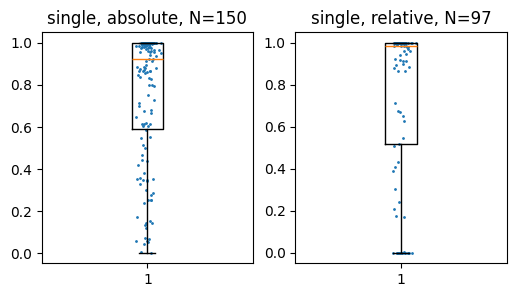

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

rng = np.random.default_rng()

sabs = [q.absolute for v, q in single if not np.isnan(q.absolute)]
srel = [q.relative for v, q in single if not np.isnan(q.relative)]

ax1.boxplot(sabs)
ax1.scatter(rng.normal(loc=1, scale=0.025, size=len(sabs)), sabs, s=1)
ax1.set_title(f"single, absolute, N={len(sabs)}")
ax2.boxplot(srel)
ax2.scatter(rng.normal(loc=1, scale=0.025, size=len(srel)), srel, s=1)
ax2.set_title(f"single, relative, N={len(srel)}")

plt.show()

In [7]:
pressure = list(parse_pressure("expert-quantile-pressure.txt"))

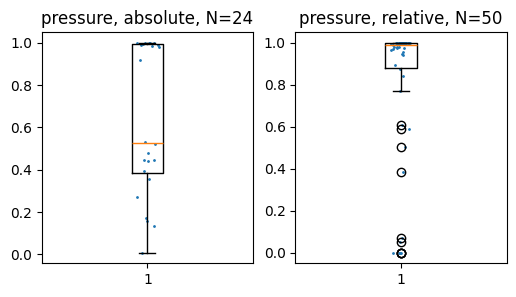

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

sabs = [q.absolute for v, p, q in pressure if not np.isnan(q.absolute)]
srel = [q.relative for v, p, q in pressure if not np.isnan(q.relative)]

ax1.boxplot(sabs)
ax1.scatter(rng.normal(loc=1, scale=0.025, size=len(sabs)), sabs, s=1)
ax1.set_title(f"pressure, absolute, N={len(sabs)}")
ax2.boxplot(srel)
ax2.scatter(rng.normal(loc=1, scale=0.025, size=len(srel)), srel, s=1)
ax2.set_title(f"pressure, relative, N={len(srel)}")

plt.show()